# Supplementary Figure 3.4: Step size before the bound-crossing step

Tests whether the *size of the step immediately preceding the one used to
compute the bound* predicts termination, beyond what a fixed decision bound
predicts on its own.

## Logic

`pigeon.data.get_bounds` estimates the bound as the midpoint of the pigeon's
position at two adjacent time points, `DT` and `DT+1` steps into the trial
(`DT` is the same column already in the data table: `dts = max(0, rts - ndts - 1)`).
So:

- The **bound-computing step** is step number `DT+1` (positions `DT` → `DT+1`).
- The **full step immediately before it** is step number `DT`
  (positions `DT-1` → `DT`), size = `steps[DT-1] - steps[DT-2]` (0-indexed array).

This matches the requested convention directly: if the bound was computed in
the middle of step 3 (`DT=2`), the preceding step is step 2, plotted at
`step=2`. No new step-counting logic is needed — `DT` *is* the step-number
x-axis.

**Step-size metric**: signed step in the direction of the eventual choice
(`(steps[DT-1]-steps[DT-2]) * sign(choice)`), i.e. progress toward the side
ultimately chosen — tests whether choices follow steps that specifically
pushed the decision variable toward the bound that was crossed.

## Confound and control

Expected step size covaries with bound height and RT (shorter/higher-bound
trials mechanically require bigger average steps to cross in fewer steps,
even under a truly fixed threshold — a pure selection effect of conditioning
on step number). To control for this, each real subject/block is matched to
a simulated counterpart generated with `bound_type='fixed'`
(`get_simulated_data_table`): a constant bound equal to that subject's own
median `|bound|` in that block, with the same generative SNR(s), so any
apparent step-size-vs-step-number relationship in the simulation reflects
*only* the mechanical/selection effect of a fixed threshold. Comparing real
vs. this matched null isolates genuine step-size-dependent termination.

Same block/dataset convention as `Table_slopeAnalyses` / `Figure03S03_sequentialAnalysis`:
**OL blocks 1–3** (raw 6-block numbering, `combine_snr=False`).

## Plot and test

For each block, one panel: x = step number (`DT`), y = per-subject
**real − matched-simulated** difference in mean signed step size at that `DT`
(each point is one participant's real trials, `min 5` per subject/DT cell, minus
their matched fixed-bound-simulated counterpart). Marker style (open circle,
white face, gray edge, size 5) matches the per-participant-vs-DT/RT convention
used in `Figure03S01_congruenceByRT` and `Figure05S01_boundDiffByDT`.

For each `DT` value within each block, a paired (subject-matched)
Wilcoxon signed-rank test compares real vs. matched-simulated per-subject
means for a median difference of zero. The red line is the median difference
at each `DT`; its per-point marker is filled if that test is significant
(p < 0.05) at that `DT`, open otherwise.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.simulate import get_simulated_data_table
from pigeon.pathDefaults import FIGURES_DIR

RNG = np.random.default_rng(12345)

## Load real data and set analysis parameters

`BLOCKS`: raw 6-block OL numbering, blocks 1–3 (matches `Figure03S03_sequentialAnalysis`).
`DT_RANGE`: step numbers 2–6 (DT ≥ 2 is already required by `get_good_trial_array`).
`MIN_TRIALS`: minimum trials per subject per DT to include that (subject, DT)
cell in the per-subject mean. `N_SIM_REPS`: number of independent simulated
blocks generated per subject (concatenated) to give the matched-simulated
null many more trials than the single real block — real trial counts per
subject/DT are fixed by the recorded data, but the simulated null is cheap to
oversample, which increases the number of subjects with enough simulated
trials at each DT to pair against the real data (particularly at higher DT,
where real trials are sparser).

In [2]:
BLOCKS     = [1, 2, 3]   # raw 6-block numbering, same convention as Table_slopeAnalyses
DT_RANGE   = np.arange(2, 7)  # step numbers (DT values) to include
MIN_TRIALS = 5           # minimum trials per subject per DT cell
N_SIM_REPS = 10          # independent simulated blocks per subject, concatenated

data_table_ol = get_data_table(task_type='OL', combine_snr=False)

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h34.58.360.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h07.36.399.csv
 49: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h09.54.461.csv
 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h41.01.524.csv


## Step-size extraction

For each good trial, `DT` is the step number of the step immediately before
the bound-computing step. Its signed size (toward the eventual choice) is
`(steps[DT-1] - steps[DT-2]) * choice_sign`, using the 0-indexed cumulative
position array already stored in the `steps` column.

In [3]:
def preceding_step_sizes(df, lg):
    # Return a DataFrame [subject_index, DT, step_size] of signed preceding-step
    # sizes (toward the eventual choice) for good trials with DT in DT_RANGE.
    sub = df[lg]
    subj_idx = sub['subject_index'].to_numpy()
    dt_arr   = sub['DT'].to_numpy()
    choice_pm = sub['choice'].to_numpy(dtype=float) * 2 - 1
    steps_col = sub['steps'].to_numpy()

    rows = []
    for si, dt, ch, steps in zip(subj_idx, dt_arr, choice_pm, steps_col):
        if not np.isfinite(dt) or dt < DT_RANGE[0] or dt > DT_RANGE[-1]:
            continue
        dt = int(dt)
        s = steps[np.isfinite(steps)] if steps is not None else np.array([])
        if dt - 1 >= len(s):   # need s[dt-1] and s[dt-2]
            continue
        prev_pos = s[dt - 2] if dt >= 2 else 0.0
        step_size = (s[dt - 1] - prev_pos) * ch
        rows.append((si, dt, step_size))

    return pd.DataFrame(rows, columns=['subject_index', 'DT', 'step_size'])


def per_subject_mean_by_dt(step_df, min_trials=MIN_TRIALS):
    # Return {subject_index: {DT: mean_step_size}} for cells with >= min_trials.
    out = {}
    for subj, grp in step_df.groupby('subject_index'):
        means = {}
        for dt, dgrp in grp.groupby('DT'):
            if len(dgrp) >= min_trials:
                means[int(dt)] = dgrp['step_size'].mean()
        if means:
            out[subj] = means
    return out

## Real vs. matched fixed-bound simulated data, per block

For each block, restrict to that block, then simulate `N_SIM_REPS` matched
counterparts with `bound_type='fixed'` (constant bound per subject = that
subject's own median `|bound|` in that block) and concatenate them into one
larger simulated pool per subject, before computing per-subject mean
preceding-step size by `DT` for both real and simulated data.

In [4]:
results = {}

for block in BLOCKS:
    real_block = data_table_ol[data_table_ol['block_index'] == block].reset_index(drop=True)
    sim_reps = [get_simulated_data_table(data_table=real_block, bound_type='fixed', rng=RNG)
                for _ in range(N_SIM_REPS)]
    sim_block = pd.concat(sim_reps, ignore_index=True)

    good_real = get_good_trial_array(real_block) & real_block['bound'].notna()
    good_sim  = get_good_trial_array(sim_block)  & sim_block['bound'].notna()

    steps_real = preceding_step_sizes(real_block, good_real)
    steps_sim  = preceding_step_sizes(sim_block,  good_sim)

    means_real = per_subject_mean_by_dt(steps_real)
    means_sim  = per_subject_mean_by_dt(steps_sim)
    common = sorted(set(means_real) & set(means_sim))

    results[block] = dict(steps_real=steps_real, steps_sim=steps_sim,
                           means_real=means_real, means_sim=means_sim,
                           common=common)

    print(f'OL block {block}: {good_real.sum()} real / {good_sim.sum()} simulated good trials '
          f'({N_SIM_REPS} reps), {len(common)} subjects with usable data in both')

OL block 1: 3562 real / 23558 simulated good trials (10 reps), 46 subjects with usable data in both


OL block 2: 3070 real / 23178 simulated good trials (10 reps), 46 subjects with usable data in both


OL block 3: 1448 real / 12665 simulated good trials (10 reps), 43 subjects with usable data in both


## Per-DT paired test: real vs. matched simulated

For each `DT` value within each block, gather the subjects who have both a
real and a matched-simulated per-subject mean at that `DT` (each backed by
`>= MIN_TRIALS` trials), and run a paired Wilcoxon signed-rank test on the
real-vs-simulated difference (median difference = 0 under the null that the
real data match the fixed-bound simulated null at that step number).

In [5]:
MIN_PAIRS = 5  # minimum paired subjects required to run a test at a given DT

def paired_test_by_dt(means_real, means_sim, dt_range):
    # For each DT, paired Wilcoxon signed-rank test on real vs. matched
    # simulated per-subject means (subjects with data in both). Returns
    # {DT: (p_value, n_pairs)}; p_value is NaN if too few paired subjects.
    common_subjects = sorted(set(means_real) & set(means_sim))
    out = {}
    for dt in dt_range:
        real_vals, sim_vals = [], []
        for subj in common_subjects:
            if dt in means_real[subj] and dt in means_sim[subj]:
                real_vals.append(means_real[subj][dt])
                sim_vals.append(means_sim[subj][dt])
        n = len(real_vals)
        if n >= MIN_PAIRS and np.any(np.array(real_vals) != np.array(sim_vals)):
            _, p = scipy.stats.wilcoxon(real_vals, sim_vals)
        else:
            p = np.nan
        out[dt] = (p, n)
    return out


print(f'{"block":>6} {"DT":>4} {"n pairs":>8} {"p":>10}')
for block in BLOCKS:
    r = results[block]
    r['dt_tests'] = paired_test_by_dt(r['means_real'], r['means_sim'], DT_RANGE)
    for dt in DT_RANGE:
        p, n = r['dt_tests'][dt]
        p_str = f'{p:.3g}' if np.isfinite(p) else 'n/a'
        print(f'{block:>6} {dt:>4} {n:>8} {p_str:>10}')

 block   DT  n pairs          p
     1    2       42   0.000842
     1    3       38      0.528
     1    4       36      0.603
     1    5       30     0.0961
     1    6       22      0.424
     2    2       24    0.00719
     2    3       32       0.35
     2    4       35     0.0327
     2    5       31     0.0246
     2    6       27      0.953
     3    2       21    0.00628
     3    3       25      0.241
     3    4       25       0.23
     3    5       14      0.952
     3    6       11     0.0137


## Figure: preceding step size vs. step number, real − matched simulated

One panel per OL block. Each point is one participant's **real − matched-simulated**
per-subject mean signed preceding-step size (toward the eventual choice) at a given
step number (`DT`) — i.e. the paired difference tested above, plotted directly rather
than showing the two raw series side by side. Marker style (open circle, white face,
gray edge, size 5, horizontally jittered) matches the per-participant-vs-DT/RT
convention used in `Figure03S01_congruenceByRT` and `Figure05S01_boundDiffByDT`.

The red line is the median difference at each `DT`; the small circle marker on the
line is filled if the paired Wilcoxon test computed above is significant at that `DT`
(p < 0.05) and open otherwise — same significance-marking convention as
`Figure05S01_boundDiffByDT`. Saves to `Figure03_S04.pdf`.

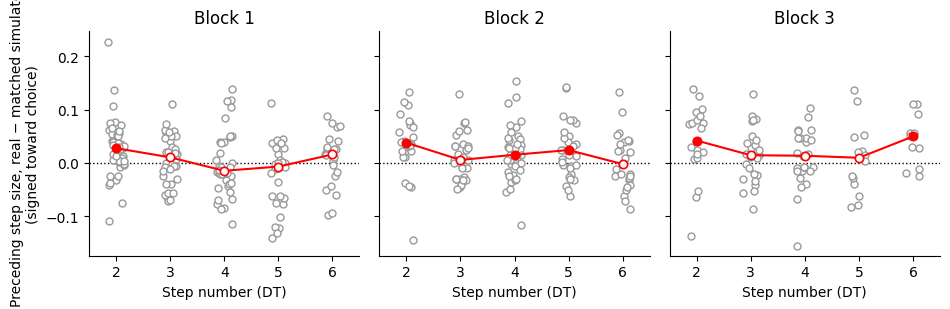

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S04.pdf


In [6]:
fig, axs = plt.subplots(1, len(BLOCKS), figsize=(3.2 * len(BLOCKS), 3.2), sharey=True)

JITTER = 0.15

for j, block in enumerate(BLOCKS):
    ax = axs[j]
    r = results[block]
    means_real, means_sim = r['means_real'], r['means_sim']
    common = r['common']

    ax.axhline(0, color='k', linestyle=':', linewidth=1)

    medians = np.full(len(DT_RANGE), np.nan)
    sig     = np.zeros(len(DT_RANGE), dtype=bool)
    for di, dt in enumerate(DT_RANGE):
        diffs = np.array([means_real[s][dt] - means_sim[s][dt] for s in common
                           if dt in means_real[s] and dt in means_sim[s]])
        if len(diffs) == 0:
            continue

        # Per-participant marker style (open circle, white face, gray edge,
        # size 5) matches the convention used in Figure03S01 and Figure05S01.
        jitter = RNG.uniform(-JITTER, JITTER, size=len(diffs))
        ax.plot(dt + jitter, diffs, 'o', markerfacecolor='white', markeredgecolor='0.6',
                markersize=5, zorder=2)

        medians[di] = np.median(diffs)
        p, n = r['dt_tests'][dt]
        sig[di] = np.isfinite(p) and p < 0.05

    # Median difference across subjects at each DT — red line, with a small
    # circle marker flagging per-DT significance (the paired Wilcoxon test
    # computed above, real vs. matched simulated): filled = p<0.05, open =
    # not significant. Same convention as Figure05S01_boundDiffByDT.
    ok = np.isfinite(medians)
    ax.plot(DT_RANGE[ok], medians[ok], 'r-', linewidth=1.5, zorder=4)
    for di in np.where(ok)[0]:
        face = 'red' if sig[di] else 'white'
        ax.plot(DT_RANGE[di], medians[di], 'ro', markerfacecolor=face,
                markersize=6, zorder=5, markeredgewidth=1.2)

    ax.set_xlim(DT_RANGE[0] - 0.5, DT_RANGE[-1] + 0.5)
    ax.set_xlabel('Step number (DT)')
    ax.set_title(f'Block {block}')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axs[0].set_ylabel('Preceding step size, real − matched simulated\n(signed toward choice)')

plt.tight_layout()
out = FIGURES_DIR / 'Figure03_S04.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')